# REFIT House 1: Raw Data Inspection and Cleaning (Part 1)

This notebook takes the **raw** REFIT data for House 1, checks its quality, cleans it, and produces a 1-minute dataset.

**What the notebook does, in order**
1. Load the raw House 1 files and check them (rows, timestamps, order, missing readings).
2. Sort the readings and remove duplicate timestamps with one stated rule.
3. Check the time between readings and look for impossible or extreme values.
4. Resample to 1-minute average power.
5. Fill only short gaps (2 minutes or less) and leave longer outages missing.
6. Plot raw versus cleaned power for the aggregate and two appliances.
7. Run checks on the final data and save the results.

**Input:** the raw House 1 CSV files inside a folder called `raw/` in the project folder.

**Output:** the cleaned CSV, summary tables and figures inside `outputs/house1/` and `figures/`.

**Units:** all power values are in watts (W).

## 1. Setup

The settings below are the only values you may want to change.

- `MAX_AGGREGATE_W`: 23,000 W is a screening assumption. House 1's actual supply rating is not verified in the supplied documentation, so a reading above this threshold is flagged as suspect rather than proved impossible.
- `MAX_APPLIANCE_W`: 4,000 W follows the supplied cleaned REFIT notes. It is a screening threshold, not a verified rating for every appliance.
- `MAX_GAP_MINUTES`: fill only complete internal gaps of up to two missing minutes, subject to the safeguards below.
- The supplied House 1 README confirms `Appliance1` as the fridge and `Appliance5` as the washing machine at the start of the study. Sensors may have been moved later.

**Important:** Part 1 of the raw dataset uses zero for unavailable sensors as well as genuine off states; Part 2 uses NaN for unavailable sensors. Keep zeros because these cases cannot reliably be separated, but do not assume that Part 1 has complete sensor coverage merely because it has no NaNs.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW_DIR = ROOT / "raw"
OUTPUT_DIR = ROOT / "outputs" / "house1"
FIGURE_DIR = ROOT / "figures"

CHANNELS = ["Aggregate"] + [f"Appliance{i}" for i in range(1, 10)]
PLOT_CHANNELS = {"Aggregate": "Whole home", "Appliance1": "Fridge", "Appliance5": "Washing machine"}

MAX_AGGREGATE_W = 23000
MAX_APPLIANCE_W = 4000
MAX_GAP_MINUTES = 2

# Both parts are required; do not silently run on an incomplete dataset.
house1_files = [RAW_DIR / "RAW_House1_Part1.csv", RAW_DIR / "RAW_House1_Part2.csv"]
for path in house1_files:
    if not path.is_file():
        raise FileNotFoundError(f"Missing required file: {path}. Extract both raw House 1 parts into raw/.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)
print("House 1 files:", [p.name for p in house1_files])

Project folder: C:\Users\archi\Desktop\REFIT Data Cleaning\-REFIT-Data-Cleaning-and-Appliance-Disaggregation
House 1 files: ['RAW_House1_Part1.csv', 'RAW_House1_Part2.csv']


## 2. Load and inspect the raw files

Each raw file has a text `Time` column, a numeric `Unix` column (seconds since 1 January 1970) and the power columns.

- Use `Unix` consistently to order and group readings. A numeric timestamp can still contain clock errors.
- Compare the text `Time` field with the Unix-derived time on every 100th row. Report differences in **seconds without rounding** so small disagreements remain visible. Sampling keeps memory use low but does not check every text timestamp.
- This compares the two fields' internal consistency; it does not independently establish their timezone. Keep the recorded clock without applying a global hour shift or claiming verified UTC.
- Convert power columns to numbers; non-numeric values become missing. Part 1 zeros can conceal unavailable sensors, as noted above.

In [2]:
frames = []
audit_rows = []

for path in house1_files:
    frame = pd.read_csv(path, usecols=["Unix"] + CHANNELS)
    frame["Unix"] = pd.to_numeric(frame["Unix"], errors="coerce")
    for channel in CHANNELS:
        frame[channel] = pd.to_numeric(frame[channel], errors="coerce").astype("float32")

    sample = pd.read_csv(path, usecols=["Time", "Unix"], skiprows=lambda i: i > 0 and i % 100 != 0)
    text_time = pd.to_datetime(sample["Time"], errors="coerce")
    unix_time = pd.to_datetime(pd.to_numeric(sample["Unix"], errors="coerce"), unit="s", errors="coerce")
    time_difference_seconds = (text_time - unix_time).dt.total_seconds()

    audit_rows.append({
        "file": path.name,
        "rows": len(frame),
        "first_timestamp": pd.to_datetime(frame["Unix"].min(), unit="s"),
        "last_timestamp": pd.to_datetime(frame["Unix"].max(), unit="s"),
        "unreadable_unix_values": int(frame["Unix"].isna().sum()),
        "rows_out_of_order": int((frame["Unix"].diff() < 0).sum()),
        "unreadable_time_text_in_sample": int(text_time.isna().sum()),
        "time_minus_unix_seconds_in_sample": str(time_difference_seconds.value_counts().sort_index().to_dict()),
    })
    frames.append(frame)

file_audit = pd.DataFrame(audit_rows)
display(file_audit.T)

data = pd.concat(frames, ignore_index=True)
del frames

print("Total raw rows:", f"{len(data):,}")
print("Rows out of order after joining the files:", int((data["Unix"].diff() < 0).sum()))

missing_raw = data[CHANNELS].isna().sum().rename("missing_readings").to_frame()
missing_raw["missing_percent"] = (100 * data[CHANNELS].isna().mean()).round(3)
display(missing_raw)

,0,1
file,RAW_House1_Part1.csv,RAW_House1_Part2.csv
rows,4377877,4140886
first_timestamp,2013-10-09 14:06:17,2014-06-27 21:57:49
last_timestamp,2014-10-01 01:27:07,2015-07-10 11:56:32
unreadable_unix_values,0,0
rows_out_of_order,1,0
unreadable_time_text_in_sample,0,0
time_minus_unix_seconds_in_sample,"{0.0: 22602, 1.0: 21176}","{0.0: 21298, 1.0: 20110}"


Total raw rows: 8,518,763
Rows out of order after joining the files: 2


,missing_readings,missing_percent
Aggregate,188973,2.218
Appliance1,437890,5.140
Appliance2,459468,5.394
Appliance3,311961,3.662
Appliance4,510963,5.998
Appliance5,497223,5.837
Appliance6,342337,4.019
Appliance7,232752,2.732
Appliance8,390705,4.586
Appliance9,1911811,22.442


## 3. Sort and remove duplicate timestamps

The two files can overlap, so the same timestamp may appear more than once.

**Rule used:**
1. Drop rows whose timestamp could not be read.
2. Sort all rows by time (a stable sort keeps the original order for equal timestamps).
3. If a timestamp appears more than once, keep the **last non-missing value of each column**. Because the files are joined in order, the later file wins.

Timestamps where the duplicate rows disagree are counted and reported, because this rule cannot prove which value is correct.

**Important trade-off:** `groupby(...).last()` picks the last *non-missing value separately for each channel*, so a resolved timestamp can combine values from different source rows. With conflicting duplicates, this is a deterministic convenience rule, not evidence that the selected measurement is the true one. We keep the conflict count visible and do not infer which sensor reading is correct.

In [3]:
bad_timestamps = int(data["Unix"].isna().sum())

data = data.dropna(subset=["Unix"])
data["datetime"] = pd.to_datetime(data["Unix"], unit="s")
data = data.drop(columns="Unix").sort_values("datetime", kind="stable").set_index("datetime")

extra_duplicate_rows = int(data.index.duplicated().sum())
duplicate_rows = data[data.index.duplicated(keep=False)]
disagree = (duplicate_rows.groupby(level=0).nunique() > 1).any(axis=1)
conflicting_timestamps = int(disagree.sum())

readings = data.groupby(level=0).last()

print("Rows dropped for unreadable timestamps:", bad_timestamps)
print("Extra rows with a repeated timestamp:", extra_duplicate_rows)
print("Repeated timestamps where the values disagree:", conflicting_timestamps)
print("Unique timestamps kept:", f"{len(readings):,}")
print("Time range:", readings.index.min(), "to", readings.index.max())
assert readings.index.is_unique and readings.index.is_monotonic_increasing

Rows dropped for unreadable timestamps: 0
Extra rows with a repeated timestamp: 1211048
Repeated timestamps where the values disagree: 270767
Unique timestamps kept: 7,307,715
Time range: 2013-10-09 14:06:17 to 2015-07-10 11:56:32


## 4. Time between readings

REFIT meters report roughly every few seconds, but the interval is not perfectly regular. The table shows the real spacing between consecutive unique timestamps, and the counts show how often the meter went quiet for longer than a minute.

In [4]:
seconds_between = readings.index.to_series().diff().dt.total_seconds().dropna()

display(seconds_between.describe(percentiles=[0.5, 0.9, 0.99]).to_frame("seconds"))
print("Most common intervals (seconds, rounded):")
display(seconds_between.round().value_counts().head(5).rename("count").to_frame())

print("Intervals longer than 60 seconds:", int((seconds_between > 60).sum()))
print("Intervals longer than 1 hour:", int((seconds_between > 3600).sum()))
print("Longest silence between readings:", pd.to_timedelta(seconds_between.max(), unit="s"))

,seconds
count,7.307714e+06
mean,7.553910e+00
std,1.394744e+03
min,1.000000e+00
50%,7.000000e+00
90%,1.300000e+01
99%,1.500000e+01
max,3.594414e+06


Most common intervals (seconds, rounded):


,count
datetime,
7.0,1723366
2.0,1229144
6.0,1097095
8.0,762820
13.0,452585


Intervals longer than 60 seconds: 4040
Intervals longer than 1 hour: 21
Longest silence between readings: 41 days 14:26:54


## 5. Impossible and extreme values

A reading is marked **invalid** if it is:
- negative,
- infinite, or
- above the limit set in the setup cell (23,000 W for the aggregate, 4,000 W for each appliance).

The table also shows the 99.9th percentile, the maximum and the number of exact zeros. Zeros may represent an off appliance, but Part 1 also uses them for unavailable sensors. A zero run is not enough on its own to identify an outage.

Invalid readings are replaced by missing values. Sharp changes within the chosen limits are retained. The screen may still reject a genuine unusually high reading.

**Threshold caveat:** 23,000 W (aggregate) and 4,000 W (each appliance) are analyst-selected screening thresholds, **not verified physical limits of each meter/appliance**. High readings might be genuine. The value audit below reports the number above each threshold; a later study could review examples and test threshold sensitivity.

In [5]:
limits = pd.Series({c: MAX_AGGREGATE_W if c == "Aggregate" else MAX_APPLIANCE_W for c in CHANNELS})

negative = readings < 0
too_high = readings.gt(limits, axis="columns")
invalid = negative | too_high

value_audit = pd.DataFrame({
    "observed_readings": readings.notna().sum(),
    "zero_readings": (readings == 0).sum(),
    "negative_readings": negative.sum(),
    "above_limit_readings": too_high.sum(),
    "p99.9_W": readings.quantile(0.999).round(1),
    "max_W": readings.max().round(1),
})
display(value_audit)

screened = readings.mask(invalid)
print("Readings marked invalid in total:", int(invalid.sum().sum()))

,observed_readings,zero_readings,negative_readings,above_limit_readings,p99.9_W,max_W
Aggregate,7143517,8,0,65,10683.0,29159.0
Appliance1,6910730,5277308,0,783,107.0,76677.0
Appliance2,6887536,4465321,0,35,61.0,98301.0
Appliance3,7027234,4175218,0,116,196.0,73725.0
Appliance4,6861824,6833407,0,1545,1362.0,98301.0
Appliance5,6852910,6700899,0,191,2345.0,73725.0
Appliance6,7001651,6936831,0,33,2285.0,37610.0
Appliance7,7102400,6342126,0,373,48.0,98299.0
Appliance8,6952711,5653689,0,151,54.0,98301.0
Appliance9,5602453,1472,0,43,1045.0,65535.0


Readings marked invalid in total: 3335


## 6. Resample to 1-minute average power

All valid readings inside each minute are averaged. The result is the average power in watts for that minute.

A minute with no valid readings stays **missing**. It is never set to zero, because zero would wrongly say the appliance was off.

In [6]:
minute = screened.resample("1min").mean()
readings_per_minute = readings.resample("1min").size()

print("Number of 1-minute rows:", f"{len(minute):,}")
print("Minutes with no raw readings at all:", int((readings_per_minute == 0).sum()))
print("Aggregate minutes missing before filling:", int(minute["Aggregate"].isna().sum()))

Number of 1-minute rows: 920,031
Minutes with no raw readings at all: 115077
Aggregate minutes missing before filling: 115132


## 7. Fill only short gaps caused by absent/empty samples

We interpolate **at most two consecutive missing minutes**, with valid values on both sides. We **do not fill** a minute when it contains one or more non-missing raw readings but *every one of them* was rejected by the extreme-value rule. These rejected-only minutes stay missing for human review. (A minute containing a mixture of valid and rejected readings retains its mean of the valid readings.)

We use linear interpolation for this offline cleaning exercise; it is not a causal method for real-time NILM. Long outages and gaps touching rejected-only minutes remain missing. The same simple rule is applied separately to each channel.

In [7]:
# Minutes with at least one observed channel value, but zero accepted values:
# keep these missing rather than interpolating across rejected measurements.
raw_counts = readings.resample("1min").count()
valid_counts = screened.resample("1min").count()
rejected_only = (raw_counts > 0) & (valid_counts == 0)


def fill_short_gaps(series, max_gap, blocked):
    missing = series.isna()
    run_id = (missing != missing.shift(fill_value=False)).cumsum()
    run_length = missing.groupby(run_id).transform("sum")
    # Do not fill any gap/run that contains a rejected-only minute.
    blocked_run = blocked.groupby(run_id).transform("any")
    is_short_safe = missing & (run_length <= max_gap) & ~blocked_run
    estimate = series.interpolate(limit_area="inside")
    was_filled = is_short_safe & estimate.notna()
    result = series.copy()
    result.loc[was_filled] = estimate.loc[was_filled]
    return result, was_filled


def find_gaps(series):
    missing = series.isna()
    if not missing.any():
        return pd.DataFrame(columns=["start", "end", "minutes"])
    run_id = (missing != missing.shift(fill_value=False)).cumsum()
    times = series.index.to_series()[missing]
    gaps = times.groupby(run_id[missing]).agg(["min", "max", "count"])
    gaps.columns = ["start", "end", "minutes"]
    return gaps.reset_index(drop=True)


cleaned = pd.DataFrame(index=minute.index)
imputed = pd.DataFrame(index=minute.index)
for channel in CHANNELS:
    cleaned[channel], imputed[channel] = fill_short_gaps(
        minute[channel], MAX_GAP_MINUTES, rejected_only[channel]
    )

gap_tables = []
for channel in CHANNELS:
    gaps = find_gaps(cleaned[channel])
    if not gaps.empty:
        gap_tables.append(gaps.assign(channel=channel))
unfilled_gaps = (pd.concat(gap_tables, ignore_index=True)[["channel", "start", "end", "minutes"]]
                 if gap_tables else pd.DataFrame(columns=["channel", "start", "end", "minutes"]))

print("Rejected-only minutes kept missing, by channel:")
display(rejected_only.sum().rename("rejected_only_minutes").to_frame())
print("Minutes interpolated, by channel:")
display(imputed.sum().rename("filled_minutes").to_frame())
print("Longest unfilled aggregate gaps:")
display(unfilled_gaps[unfilled_gaps["channel"] == "Aggregate"].sort_values("minutes", ascending=False).head(10))

Rejected-only minutes kept missing, by channel:


,rejected_only_minutes
Aggregate,1
Appliance1,48
Appliance2,0
Appliance3,0
Appliance4,150
Appliance5,21
Appliance6,0
Appliance7,27
Appliance8,10
Appliance9,0


Minutes interpolated, by channel:


,filled_minutes
Aggregate,588
Appliance1,1254
Appliance2,1283
Appliance3,616
Appliance4,641
Appliance5,1820
Appliance6,503
Appliance7,587
Appliance8,1013
Appliance9,771


Longest unfilled aggregate gaps:


,channel,start,end,minutes
304,Aggregate,2014-01-24 01:57:00,2014-03-06 16:22:00,59906
424,Aggregate,2015-05-10 23:37:00,2015-05-19 15:09:00,12453
434,Aggregate,2015-06-10 13:20:00,2015-06-18 01:38:00,10819
417,Aggregate,2015-04-03 01:44:00,2015-04-07 10:17:00,6274
413,Aggregate,2015-03-22 08:16:00,2015-03-24 15:22:00,3307
386,Aggregate,2014-08-30 12:01:00,2014-09-01 16:54:00,3174
426,Aggregate,2015-05-24 10:10:00,2015-05-26 12:08:00,2999
397,Aggregate,2014-10-27 00:06:00,2014-10-28 13:45:00,2260
416,Aggregate,2015-03-31 04:23:00,2015-04-01 16:25:00,2163
410,Aggregate,2015-03-15 10:03:00,2015-03-16 16:15:00,1813


## 8. Plots: raw versus cleaned

**Figure 1** shows one full day. The day is chosen automatically: among days with at least 95% of the aggregate minutes present, it is the day with the most washing-machine energy, so the washing machine trace has something to show.

**Figure 2** zooms in on one filled gap, if any gap was filled, so the interpolation can be checked by eye.

In both figures:
- grey dots are the raw readings, before any cleaning,
- the teal line is the cleaned 1-minute average,
- orange dots are minutes filled by interpolation.

Day plotted in Figure 1: 2015-02-08


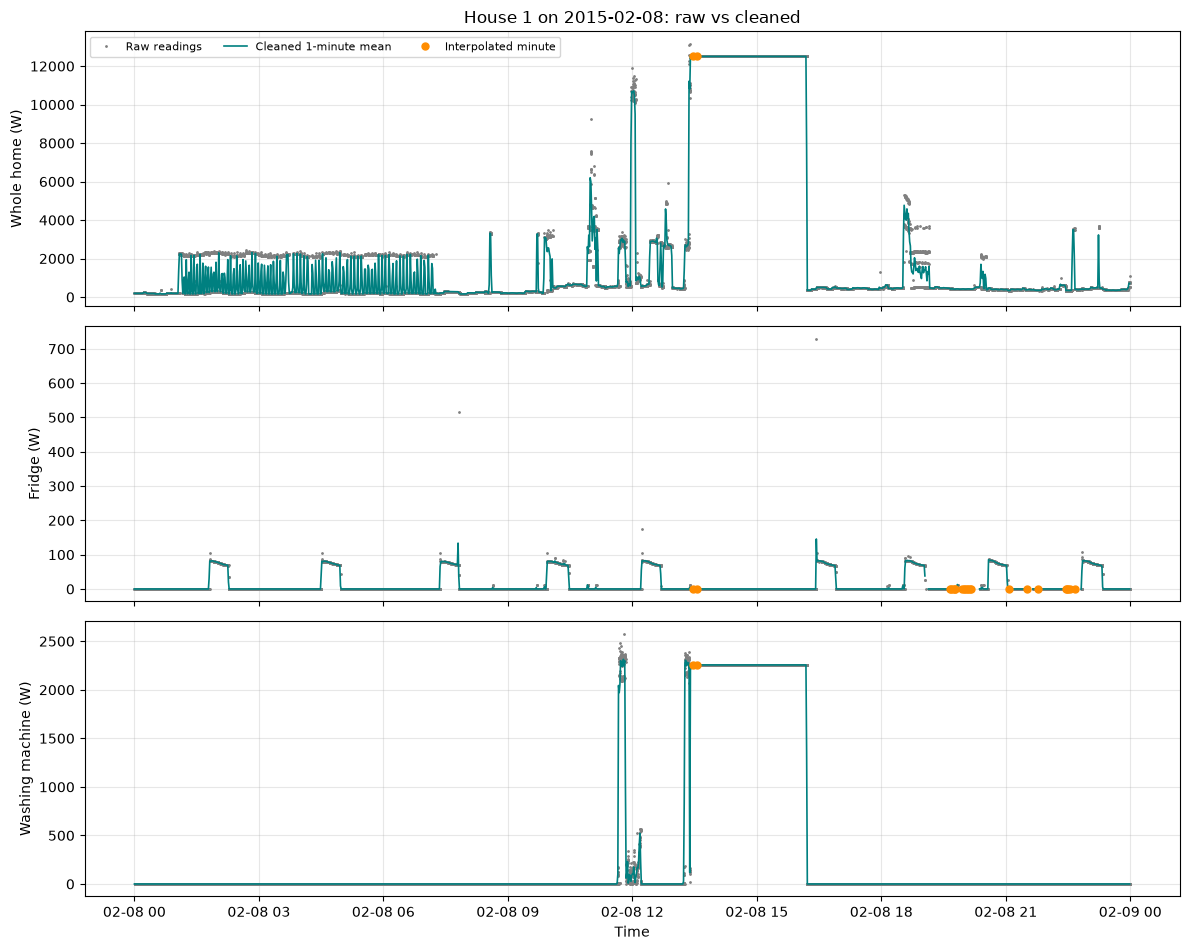

Filled gap plotted in Figure 2 around: 2013-10-14 11:12:00


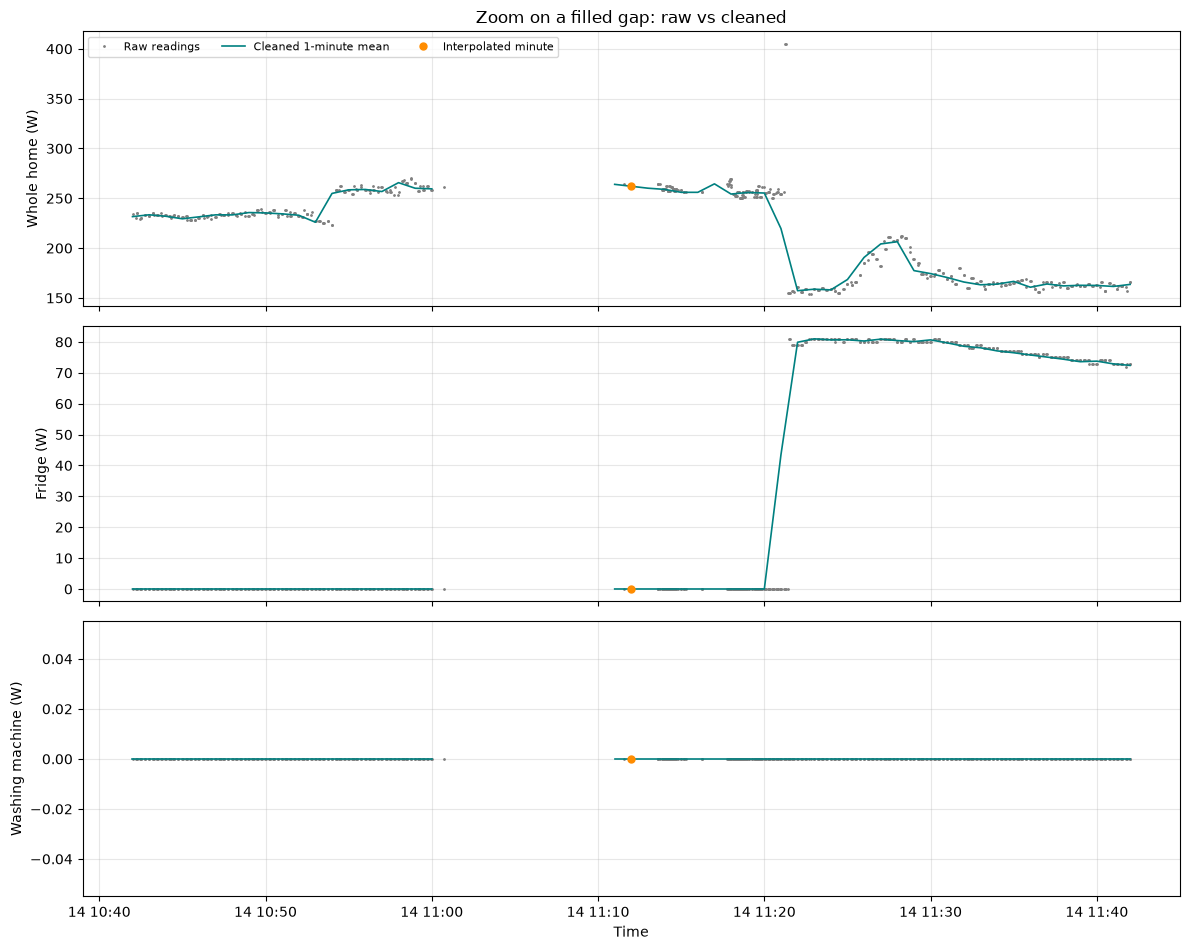

In [8]:
def plot_window(start, end, title, filename):
    fig, axes = plt.subplots(len(PLOT_CHANNELS), 1, figsize=(12, 3.2 * len(PLOT_CHANNELS)), sharex=True)
    for ax, (channel, label) in zip(axes, PLOT_CHANNELS.items()):
        raw_part = data.loc[start:end, channel]
        clean_part = cleaned.loc[start:end, channel]
        filled_part = clean_part[imputed.loc[start:end, channel]]
        ax.plot(raw_part.index, raw_part, ".", color="gray", markersize=2, label="Raw readings")
        ax.plot(clean_part.index, clean_part, color="teal", linewidth=1.2, label="Cleaned 1-minute mean")
        ax.plot(filled_part.index, filled_part, "o", color="darkorange", markersize=5, label="Interpolated minute")
        ax.set_ylabel(f"{label} (W)")
        ax.grid(alpha=0.3)
    axes[0].legend(loc="upper left", ncol=3, fontsize=8)
    axes[0].set_title(title)
    axes[-1].set_xlabel("Time")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, dpi=150)
    plt.show()


coverage = minute["Aggregate"].notna().resample("1D").sum()
washing_energy = cleaned["Appliance5"].resample("1D").sum()

candidate_days = coverage[coverage >= 0.95 * 1440].index
if len(candidate_days) == 0:
    candidate_days = coverage.index

plot_day = washing_energy.loc[candidate_days].idxmax()
day_end = plot_day + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
print("Day plotted in Figure 1:", plot_day.date())
plot_window(plot_day, day_end, f"House 1 on {plot_day.date()}: raw vs cleaned", "house1_day_raw_vs_cleaned.png")

if imputed["Aggregate"].any():
    gap_minute = imputed["Aggregate"].idxmax()
    zoom_start = gap_minute - pd.Timedelta(minutes=30)
    zoom_end = gap_minute + pd.Timedelta(minutes=30)
    print("Filled gap plotted in Figure 2 around:", gap_minute)
    plot_window(zoom_start, zoom_end, "Zoom on a filled gap: raw vs cleaned", "house1_filled_gap_zoom.png")
else:
    print("No aggregate minutes were filled, so Figure 2 is skipped.")

## 9. Check the final data and summarise

These checks stop the notebook with an error if something went wrong:
- the time index has no repeats and runs in order,
- every row is exactly one minute after the previous one,
- there are no negative values and no values above the limits,
- filled minutes were missing before, and all other minutes are unchanged.

The summary table is the main quality result to quote in `DATA.md`.

In [9]:
assert cleaned.index.is_unique and cleaned.index.is_monotonic_increasing
assert (cleaned.index.to_series().diff().dropna() == pd.Timedelta(minutes=1)).all()
assert (cleaned < 0).sum().sum() == 0
assert cleaned.gt(limits, axis="columns").sum().sum() == 0
assert not (imputed & minute.notna()).any().any()
pd.testing.assert_frame_equal(cleaned.where(~imputed), minute.where(~imputed), check_dtype=False)
assert not (imputed & rejected_only).any().any()  # Never fill rejected-only minutes

longest_unfilled = unfilled_gaps.groupby("channel")["minutes"].max().reindex(CHANNELS).fillna(0).astype(int)

summary = pd.DataFrame({
    "observed_minutes": minute.notna().sum(),
    "missing_minutes_before": minute.isna().sum(),
    "filled_minutes": imputed.sum(),
    "missing_minutes_after": cleaned.isna().sum(),
    "missing_after_percent": (100 * cleaned.isna().mean()).round(2),
    "invalid_readings_removed": invalid.sum(),
    "rejected_only_minutes_unfilled": rejected_only.sum(),
    "longest_unfilled_gap_minutes": longest_unfilled,
})
display(summary)
print("All checks passed.")

,observed_minutes,missing_minutes_before,filled_minutes,missing_minutes_after,missing_after_percent,invalid_readings_removed,rejected_only_minutes_unfilled,longest_unfilled_gap_minutes
Aggregate,804899,115132,588,114544,12.45,65,1,59906
Appliance1,802337,117694,1254,116440,12.66,783,48,59906
Appliance2,801515,118516,1283,117233,12.74,35,0,59906
Appliance3,803443,116588,616,115972,12.61,116,0,59906
Appliance4,803883,116148,641,115507,12.55,1545,150,59906
Appliance5,796475,123556,1820,121736,13.23,191,21,59906
Appliance6,804063,115968,503,115465,12.55,33,0,59906
Appliance7,804883,115148,587,114561,12.45,373,27,59906
Appliance8,803249,116782,1013,115769,12.58,151,10,59906
Appliance9,707066,212965,771,212194,23.06,43,0,59906


All checks passed.


## 10. Save the results

The files below are written to `outputs/house1/`. The cleaned CSV is large, so it is usually kept out of the GitHub repository.

The corresponding `DATA.md` describes dataset coverage, duplicate/conflict handling, threshold assumptions, and missing-data decisions. Re-run this notebook before finalizing its numeric summary: the new rejected-only safeguard can change interpolation totals.

In [10]:
cleaned.to_csv(OUTPUT_DIR / "house1_cleaned_1min.csv", index_label="timestamp")
imputed.to_csv(OUTPUT_DIR / "house1_filled_flags_1min.csv", index_label="timestamp")
summary.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index_label="channel")
value_audit.to_csv(OUTPUT_DIR / "value_audit.csv", index_label="channel")
file_audit.to_csv(OUTPUT_DIR / "source_file_audit.csv", index=False)
unfilled_gaps.to_csv(OUTPUT_DIR / "unfilled_gaps.csv", index=False)
rejected_only.to_csv(OUTPUT_DIR / "rejected_only_flags_1min.csv", index_label="timestamp")

print("Raw rows:", f"{int(file_audit['rows'].sum()):,}")
print("Time range:", readings.index.min(), "to", readings.index.max())
print("Median seconds between readings:", seconds_between.median())
print("Extra duplicate rows:", extra_duplicate_rows, "| disagreeing duplicate timestamps:", conflicting_timestamps)
print("Invalid readings removed:", int(invalid.sum().sum()))
print("1-minute rows:", f"{len(cleaned):,}")
print("Aggregate minutes still missing:", int(cleaned["Aggregate"].isna().sum()))
print("Saved files in:", OUTPUT_DIR)

Raw rows: 8,518,763
Time range: 2013-10-09 14:06:17 to 2015-07-10 11:56:32
Median seconds between readings: 7.0
Extra duplicate rows: 1211048 | disagreeing duplicate timestamps: 270767


Invalid readings removed: 3335
1-minute rows: 920,031
Aggregate minutes still missing: 114544
Saved files in: C:\Users\archi\Desktop\REFIT Data Cleaning\-REFIT-Data-Cleaning-and-Appliance-Disaggregation\outputs\house1
